<a href="https://colab.research.google.com/github/i5head/Applied-Deep-Learning/blob/main/Tutorial2_cnn_Applied_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.preprocessing import label_binarize
from tensorflow.keras.utils import to_categorical
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
# Load the MNIST dataset
(x_train_full, y_train_full), (x_test, y_test) = mnist.load_data()

In [ ]:
print(x_train_full.shape)
print(y_train_full.shape)


(60000, 28, 28)
(60000,)


In [ ]:
print(x_train_full)

[[[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 ...

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]

 [[0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  ...
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]
  [0 0 0 ... 0 0 0]]]


In [ ]:
print(x_train_full[2])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0  67 232  39   0   0   0   0   0]
 [  0   0   0   0  62  81   0   0   0   0   0   0   0   0   0   0   0   0
    0   0 120 180  39   0   0   0   0   0]
 [  0   0   0   0 126 163   0   0   0   0   0   0   0   0   0   0   0   0
    0   2 153 210  40   0   0   0   0   0]
 [  0   0   0   0 220 163   0   0   0   0   0   0   0   0   0   

In [ ]:
print(y_train_full)

[5 0 4 ... 5 6 8]


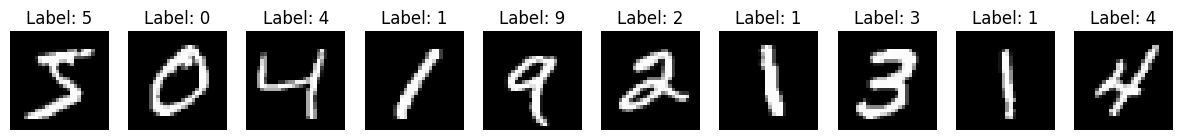

In [ ]:
#visualize some of the images
import matplotlib.pyplot as plt
import numpy as np

# Number of digits to display
num_images = 10

plt.figure(figsize=(15, 4))
for i in range(num_images):
    # pick the image
    img = x_train_full[i]

    # decode one-hot label
    label = y_train_full[i]

    # plot
    plt.subplot(1, num_images, i+1)
    plt.imshow(img, cmap="gray")
    plt.title(f"Label: {label}")
    plt.axis("off")

plt.show()

In [ ]:
# Normalize the pixel values (0-255) to range [0, 1]
x_train_full = x_train_full.astype('float32') / 255.0 # here 255 is the highest number --> all reuslts will be in [0, 1]
x_test = x_test.astype('float32') / 255.0

In [ ]:
# Reshape the input data to have a single channel (for CNN compatibility)
x_train_full = x_train_full.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

In [ ]:
print(x_train_full.shape)

(60000, 28, 28, 1)


In [ ]:
# Split training data into 50% train, 25% validation, 25% test
x_train, x_val, y_train, y_val = train_test_split(x_train_full, y_train_full, test_size=0.5, random_state=42) # random_state is a seed to fix the spliting for each computation
x_val, x_test, y_val, y_test = train_test_split(x_val, y_val, test_size=0.5, random_state=42)

In [ ]:
print(y_train[0])
# Convert labels to one-hot encoding
y_train_cat = to_categorical(y_train, 10)
y_val_cat = to_categorical(y_val, 10)
y_test_cat = to_categorical(y_test, 10)
print(y_train_cat[0])
print(y_train_cat[1].shape)

8
[0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
(10,)


In [ ]:
# Build a simple CNN model
model = tf.keras.Sequential([
    #####
    tf.keras.layers.Conv2D(4, (7, 7), input_shape=(28, 28, 1)),
    #tf.keras.layers.Conv2D(4, (7, 7)),
    tf.keras.layers.Activation('sigmoid'),
    tf.keras.layers.BatchNormalization(), # this is a way to normalise the batches

    tf.keras.layers.MaxPooling2D((3, 3)),
    #####
    tf.keras.layers.Conv2D(2, (3, 3), activation='sigmoid'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    #####
    tf.keras.layers.Flatten(), # gives us just an array
    tf.keras.layers.Dense(16, activation='sigmoid'),
    tf.keras.layers.Dense(10, activation='softmax')  # 10 classes for digits 0-9, this needs to be in aliance with the desired output classes
])

In [ ]:
# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [ ]:
print(model.summary()) #good practise to print this to see all the layers of the model

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 22, 22, 4)      │           200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 22, 22, 4)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 22, 22, 4)      │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 4)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 5, 5, 2)        │            74 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 2)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 604 (2.36 KB)

 Trainable params: 596 (2.33 KB)

 Non-trainable params: 8 (32.00 B)

None


In [ ]:
# Train the model and store the history
history = model.fit(x_train, y_train_cat, epochs=10, validation_data=(x_val, y_val_cat))

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.3533 - loss: 2.0921 - val_accuracy: 0.5252 - val_loss: 1.7361
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.6655 - loss: 1.3424 - val_accuracy: 0.7125 - val_loss: 1.0895
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7443 - loss: 0.9453 - val_accuracy: 0.7547 - val_loss: 0.8549
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7926 - loss: 0.7450 - val_accuracy: 0.8001 - val_loss: 0.6948
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8210 - loss: 0.6302 - val_accuracy: 0.8082 - val_loss: 0.6392
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8339 - loss: 0.5629 - val_accuracy: 0.8341 - val_loss: 0.5566
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8450 - loss: 0.5163 - val_accuracy: 0.8399 - val_loss: 0.5257
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8525 - loss: 0.4852 - val_accuracy: 

In [ ]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(x_test, y_test_cat)
print(f'\nTest accuracy: {test_acc}')

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8580 - loss: 0.4538

Test accuracy: 0.8579999804496765


In [ ]:
# Plot training & validation accuracy and loss, COPY THIS
def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))

    # Plot training & validation accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, label='Training Accuracy')
    plt.plot(epochs, val_acc, label='Validation Accuracy')
    plt.title('Training and Validation Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot training & validation loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, label='Training Loss')
    plt.plot(epochs, val_loss, label='Validation Loss')
    plt.title('Training and Validation Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()

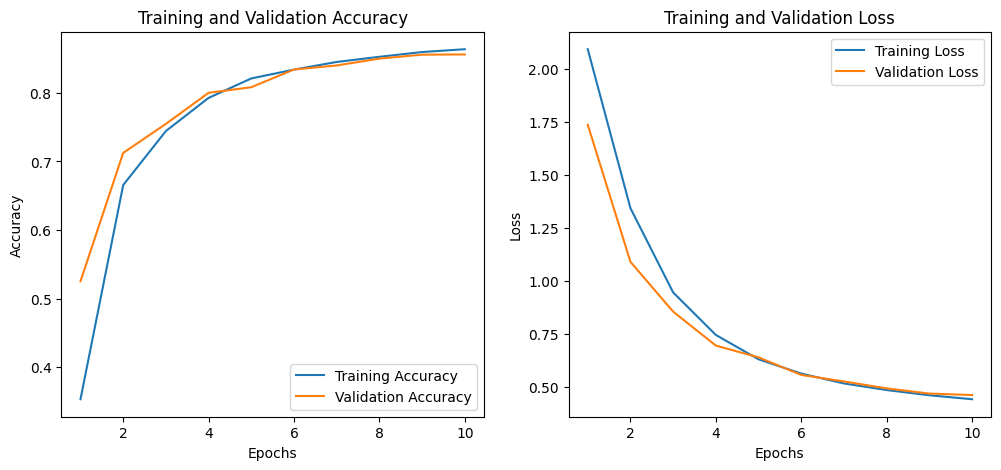

In [ ]:

# Call the function to plot the training history
plot_training_history(history)

In [ ]:
# Generate ROC curves for each digit (one-vs-rest)
def plot_roc_curves(y_true, y_pred):
    y_true_bin = label_binarize(y_true, classes=np.arange(10))

    plt.figure(figsize=(12, 8))
    colors = plt.get_cmap('tab10')

    for i in range(10):
        fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred[:, i]) # false positive rate and true positive rate - give true label and the model prediciton

        # Compute the standard ROC AUC before any transformation
        roc_auc = auc(fpr, tpr)

        # Exclude zero FPR values to avoid division by zero
        mask = fpr > 0

        plt.plot(
            tpr[mask],
            1.0 / fpr[mask],
            color=colors(i),
            lw=2,
            label=f'Digit {i} (AUC = {roc_auc:.5f})'
        )

    plt.yscale("log")
    plt.xlim([0.7, 1.0])
    plt.ylabel('1 / False Positive Rate')
    plt.xlabel('True Positive Rate')
    plt.title('ROC Curves for Each Digit')
    plt.legend(loc='lower left')
    plt.show()

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


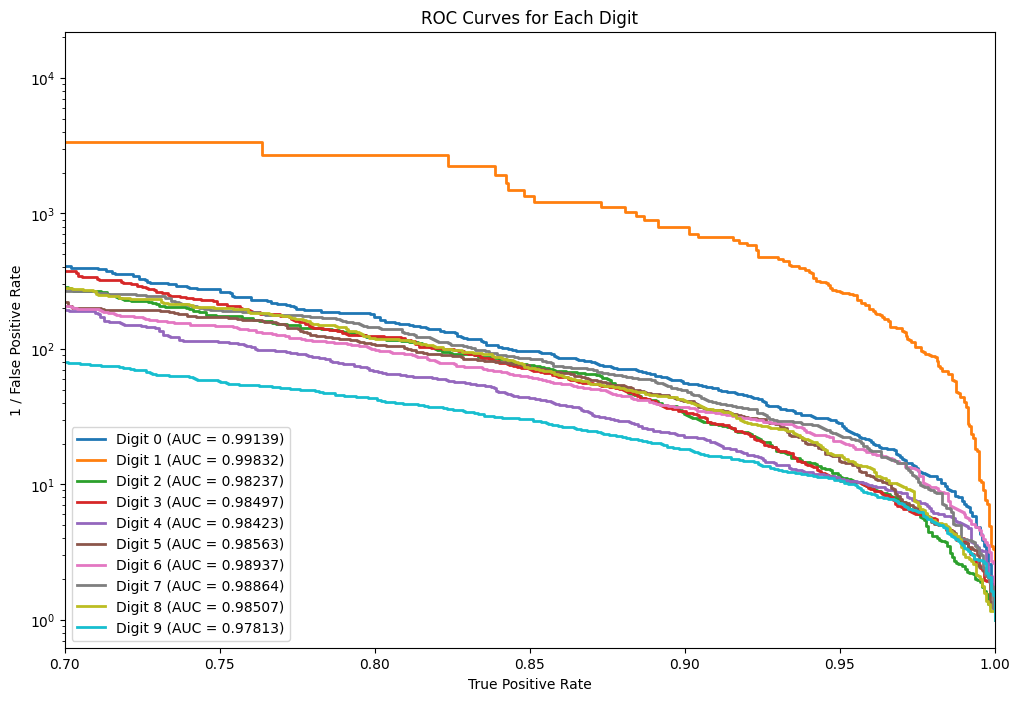

In [ ]:
# Get model predictions
y_pred_prob = model.predict(x_test)
# Plot ROC curves
plot_roc_curves(y_test, y_pred_prob)

In [ ]:
# Confusion Matrix
def plot_confusion_matrix(y_true, y_pred):
    y_pred_classes = np.argmax(y_pred, axis=1)
    cm = confusion_matrix(y_true, y_pred_classes)

    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=np.arange(10), yticklabels=np.arange(10))
    plt.title('Confusion Matrix')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()

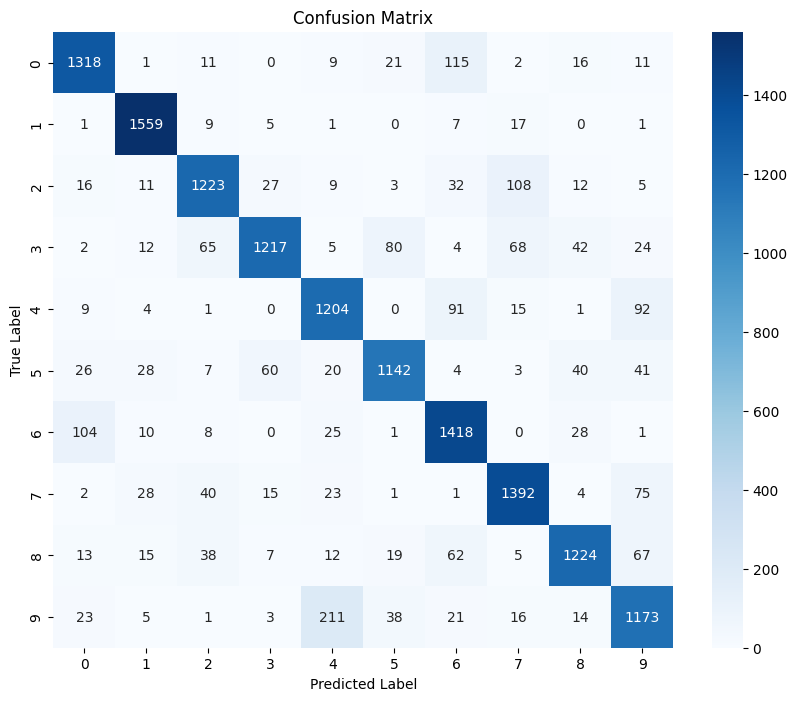

In [ ]:
# Plot confusion matrix
plot_confusion_matrix(y_test, y_pred_prob)